# 01 — EDA: Premier League matches 2000/01–2026/27

Source: football-data.co.uk season files (`data/raw/E0_*.csv`), combined by `src/load_data.py`
into `data/matches.csv`. Rerun the loader before this notebook if raw files change:

```
.venv/bin/python src/load_data.py
```

**Split plan (fixed before modelling):**

| Role | Seasons |
|---|---|
| Train | 2000/01 – 2021/22 |
| Validation | 2022/23 |
| Test | 2023/24 + 2024/25 |
| Forward test, never used for tuning | 2025/26 (complete) + 2026/27 (in progress) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)

# Validated categorical slots 1-3 (light mode) and recessive chart chrome
C = {"H": "#2a78d6", "D": "#eb6834", "A": "#1baf7a"}
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})

df = pd.read_csv("../data/matches.csv", parse_dates=["date"])
SPLITS = {"train": [f"{y}/{str(y+1)[2:]}" for y in range(2000, 2022)],
          "val": ["2022/23"], "test": ["2023/24", "2024/25"],
          "forward": ["2025/26", "2026/27"]}
df["split"] = df["season"].map({s: k for k, v in SPLITS.items() for s in v})
print(df.shape)
df.dtypes.to_frame("dtype").T

(9980, 43)


,season,date,home_team,away_team,home_goals,away_goals,result,ht_home_goals,ht_away_goals,ht_result,...,dq_result_mismatch,dq_sot_gt_shots,dq_missing_stats,dq_missing_core,dq_missing_odds,dq_odds_suspect,dq_duplicate,dq_flags,dq_ok,split
dtype,str,datetime64[us],str,str,int64,int64,str,int64,int64,str,...,bool,bool,bool,bool,bool,bool,bool,str,bool,str


## 1. Data quality

In [2]:
per_season = df.groupby("season").agg(
    matches=("date", "size"), first=("date", "min"), last=("date", "max"),
    teams=("home_team", "nunique"), flagged=("dq_ok", lambda s: (~s).sum()),
    split=("split", "first"))
per_season["complete"] = per_season["matches"] == 380
per_season

,matches,first,last,teams,flagged,split,complete
season,,,,,,,
2000/01,380,2000-08-19,2001-05-19,20,2,train,True
2001/02,380,2001-08-18,2002-05-11,20,0,train,True
2002/03,380,2002-08-17,2003-05-11,20,0,train,True
2003/04,380,2003-08-16,2004-05-15,20,0,train,True
2004/05,380,2004-08-14,2005-05-15,20,0,train,True
2005/06,380,2005-08-13,2006-05-07,20,0,train,True
2006/07,380,2006-08-19,2007-05-13,20,0,train,True
2007/08,380,2007-08-11,2008-05-11,20,0,train,True
2008/09,380,2008-08-16,2009-05-24,20,0,train,True


In [3]:
missing = df.isna().sum()
print("Missing values by column (non-zero):")
print(missing[missing > 0].to_string())
print("\n(kickoff_time only exists from 2019/20; dq_flags is empty for clean rows)")

flags = [c for c in df.columns if c.startswith("dq_") and c not in ("dq_flags", "dq_ok")]
print("\nQuality flags:")
print(df[flags].sum().to_string())
df.loc[~df["dq_ok"], ["season", "date", "home_team", "away_team", "home_shots",
                      "home_shots_on_target", "away_shots", "away_shots_on_target", "dq_flags"]]

Missing values by column (non-zero):
kickoff_time    7220
dq_flags        9977

(kickoff_time only exists from 2019/20; dq_flags is empty for clean rows)

Quality flags:
dq_result_mismatch    0
dq_sot_gt_shots       3
dq_missing_stats      0
dq_missing_core       0
dq_missing_odds       0
dq_odds_suspect       0
dq_duplicate          0


,season,date,home_team,away_team,home_shots,home_shots_on_target,away_shots,away_shots_on_target,dq_flags
80,2000/01,2000-10-14,Coventry,Tottenham,0,5,4,5,sot_gt_shots
317,2000/01,2001-04-13,Bradford,Charlton,4,8,3,8,sot_gt_shots
7988,2021/22,2021-08-15,Newcastle,West Ham,17,3,8,9,sot_gt_shots


Flagged rows are kept. The three `sot_gt_shots` rows are impossible as recorded
(e.g. 0 shots but 5 on target). Feature code should treat their shot stats as missing
rather than trust them. Results and scorelines are consistent everywhere.

## 2. Result split

In [4]:
overall = df["result"].value_counts(normalize=True).reindex(["H", "D", "A"])
print("Overall:", (overall * 100).round(1).to_dict())
by_split = (df.groupby("split")["result"].value_counts(normalize=True).unstack()
              .reindex(index=["train", "val", "test", "forward"], columns=["H", "D", "A"]) * 100).round(1)
by_split

Overall: {'H': 45.6, 'D': 24.8, 'A': 29.5}


result,H,D,A
split,,,
train,45.9,24.9,29.2
val,48.4,22.9,28.7
test,43.4,23.0,33.6
forward,42.5,27.3,30.2


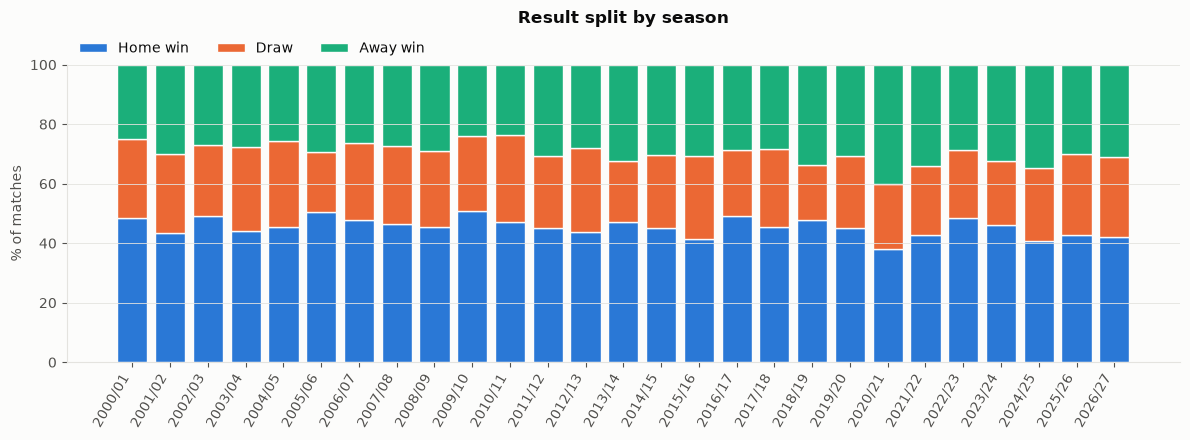

In [5]:
split_pct = (df.groupby("season")["result"].value_counts(normalize=True)
               .unstack().reindex(columns=["H", "D", "A"]) * 100)
fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(len(split_pct))
bottom = np.zeros(len(split_pct))
labels = {"H": "Home win", "D": "Draw", "A": "Away win"}
for k in ["H", "D", "A"]:
    ax.bar(x, split_pct[k], bottom=bottom, width=0.8, color=C[k], label=labels[k],
           edgecolor=SURFACE, linewidth=1)
    bottom += split_pct[k].values
ax.set_xticks(x, split_pct.index, rotation=60, ha="right")
ax.set_ylim(0, 100); ax.set_ylabel("% of matches"); ax.grid(axis="x", visible=False)
ax.set_title("Result split by season", pad=30)
ax.legend(ncols=3, loc="upper left", bbox_to_anchor=(0, 1.12), frameon=False)
plt.tight_layout(); plt.show()

## 3. Home advantage by season

In [6]:
ha = df.groupby("season").apply(lambda g: pd.Series({
    "home_win_pct": (g.result == "H").mean() * 100,
    "away_win_pct": (g.result == "A").mean() * 100,
    "home_ppg": np.select([g.result == "H", g.result == "D"], [3, 1], 0).mean(),
    "away_ppg": np.select([g.result == "A", g.result == "D"], [3, 1], 0).mean(),
    "goal_diff_per_match": (g.home_goals - g.away_goals).mean(),
}), include_groups=False)
ha["ppg_gap"] = ha.home_ppg - ha.away_ppg
ha.round(3)

,home_win_pct,away_win_pct,home_ppg,away_ppg,goal_diff_per_match,ppg_gap
season,,,,,,
2000/01,48.421,25.000,1.718,1.016,0.479,0.703
2001/02,43.421,30.000,1.568,1.166,0.297,0.403
2002/03,49.211,27.105,1.713,1.050,0.368,0.663
2003/04,43.947,27.632,1.603,1.113,0.347,0.489
2004/05,45.526,25.526,1.655,1.055,0.434,0.600
2005/06,50.526,29.211,1.718,1.079,0.437,0.639
2006/07,47.895,26.316,1.695,1.047,0.455,0.647
2007/08,46.316,27.368,1.653,1.084,0.421,0.568
2008/09,45.526,28.947,1.621,1.124,0.321,0.497


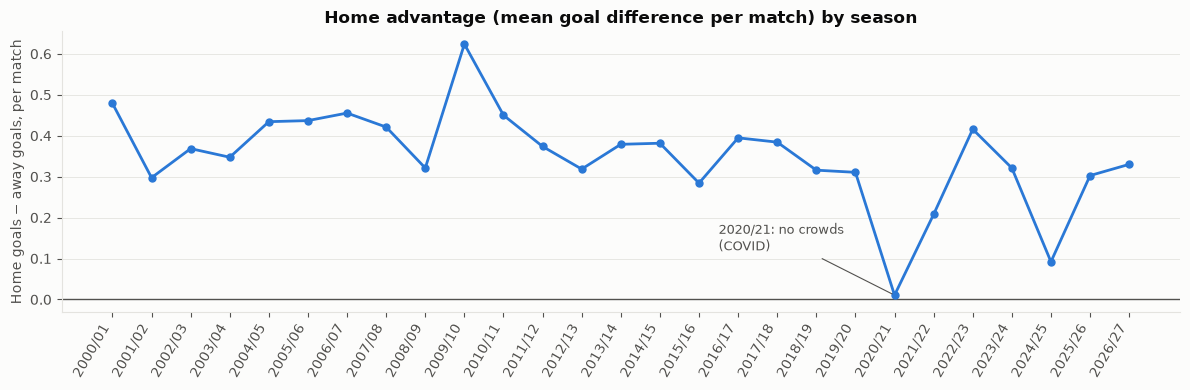

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(ha))
ax.axhline(0, color=INK2, linewidth=1)
ax.plot(x, ha["goal_diff_per_match"], color=C["H"], linewidth=2, marker="o", markersize=5)
i = list(ha.index).index("2020/21")
ax.annotate("2020/21: no crowds\n(COVID)", (i, ha["goal_diff_per_match"].iloc[i]),
            xytext=(i - 4.5, 0.12), color=INK2, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=INK2, linewidth=0.8))
ax.set_xticks(x, ha.index, rotation=60, ha="right")
ax.set_ylabel("Home goals − away goals, per match"); ax.grid(axis="x", visible=False)
ax.set_title("Home advantage (mean goal difference per match) by season")
plt.tight_layout(); plt.show()

Home advantage has shrunk over 25 years. It briefly vanished in 2020/21, when
matches were played without crowds. It has not fully returned to early-2000s levels.
Implication: a model trained on 2000–2022 may *over*-weight home advantage for
recent seasons, so season trend / recency weighting is worth testing on validation.

## 4. Odds coverage and source by season

In [8]:
odds = df.groupby("season").agg(
    coverage_pct=("odds_home", lambda s: s.notna().mean() * 100),
    source=("odds_source", lambda s: "/".join(sorted(s.dropna().unique()))),
    closing_pct=("odds_is_closing", lambda s: s.astype(float).mean() * 100),
    mean_overround=("overround", "mean"))
odds.round(3)

,coverage_pct,source,closing_pct,mean_overround
season,,,,
2000/01,100.0,books_mean_preclose,0.0,1.130
2001/02,100.0,books_mean_preclose,0.0,1.122
2002/03,100.0,b365_preclose,0.0,1.116
2003/04,100.0,b365_preclose,0.0,1.087
2004/05,100.0,b365_preclose,0.0,1.079
2005/06,100.0,avg_preclose,0.0,1.094
2006/07,100.0,avg_preclose,0.0,1.090
2007/08,100.0,avg_preclose,0.0,1.083
2008/09,100.0,avg_preclose,0.0,1.073


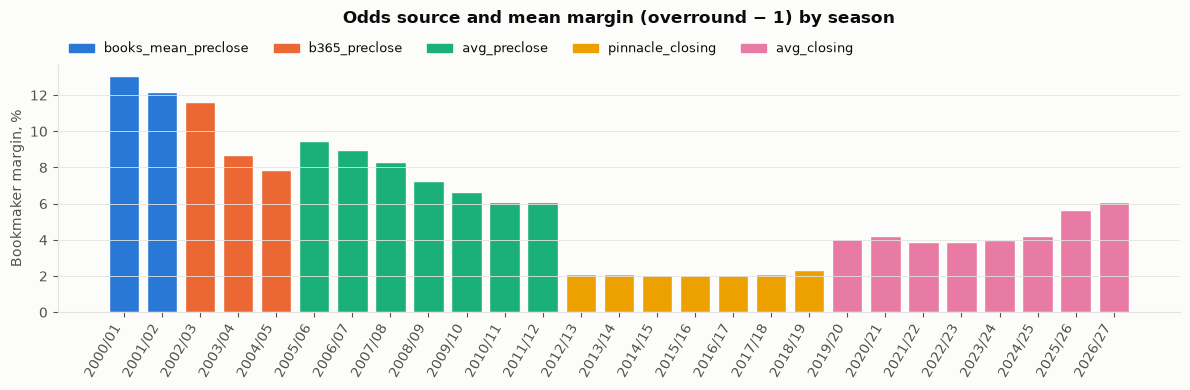

In [9]:
src_order = ["books_mean_preclose", "b365_preclose", "avg_preclose", "pinnacle_closing", "avg_closing"]
src_color = dict(zip(src_order, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(odds))
ax.bar(x, (odds["mean_overround"] - 1) * 100, width=0.8,
       color=[src_color[s] for s in odds["source"]], edgecolor=SURFACE, linewidth=1)
handles = [plt.Rectangle((0, 0), 1, 1, color=src_color[s]) for s in src_order]
ax.legend(handles, src_order, ncols=5, loc="upper left", bbox_to_anchor=(0, 1.14),
          frameon=False, fontsize=9)
ax.set_xticks(x, odds.index, rotation=60, ha="right")
ax.set_ylabel("Bookmaker margin, %"); ax.grid(axis="x", visible=False)
ax.set_title("Odds source and mean margin (overround − 1) by season", pad=30)
plt.tight_layout(); plt.show()

Coverage is 100% in every season, but the *kind* of odds changes:

- **2000/01–2001/02:** mean of several bookmakers, collected before closing (no Bet365 in these files)
- **2002/03–2004/05:** Bet365, before closing
- **2005/06–2011/12:** BetBrain market average, before closing
- **2012/13–2018/19:** Pinnacle closing (lowest margin, sharpest)
- **2019/20 onward:** market-average closing

The removed margin makes probabilities comparable in scale, but sharpness differs by
era. Closing odds are only usable as a **benchmark** to beat, or as a feature if we
accept that they are known only just before kick-off. Any odds feature must come from
the same match-time snapshot for train and test.

## 5. Market baseline (implied probabilities with margin removed)

In [10]:
P = df[["p_home_implied", "p_draw_implied", "p_away_implied"]].to_numpy()
Y = pd.get_dummies(df["result"]).reindex(columns=["H", "D", "A"]).to_numpy(float)
df["mkt_logloss"] = -np.log(np.clip((P * Y).sum(1), 1e-15, 1))
df["mkt_brier"] = ((P - Y) ** 2).sum(1)
df["mkt_correct"] = P.argmax(1) == Y.argmax(1)
df["home_baseline_correct"] = df["result"] == "H"

base = df.groupby("split").agg(
    matches=("date", "size"),
    market_accuracy=("mkt_correct", "mean"),
    always_home_accuracy=("home_baseline_correct", "mean"),
    market_logloss=("mkt_logloss", "mean"),
    market_brier=("mkt_brier", "mean"),
).reindex(["train", "val", "test", "forward"])
base.round(4)

,matches,market_accuracy,always_home_accuracy,market_logloss,market_brier
split,,,,,
train,8360,0.5373,0.4589,0.9649,0.5731
val,380,0.5553,0.4842,0.9620,0.5712
test,760,0.5776,0.4342,0.9337,0.5510
forward,480,0.4917,0.4250,1.0116,0.6071


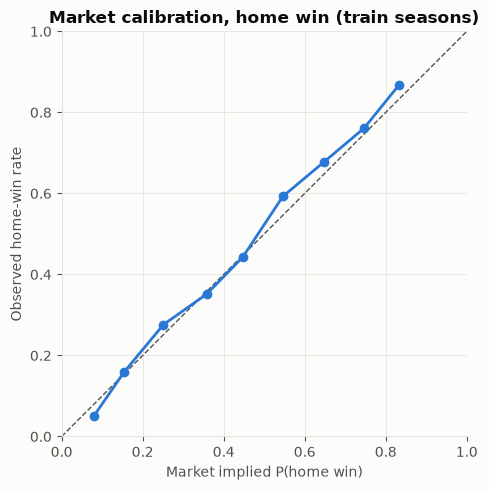

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 5))
d = df[df.split == "train"]
bins = np.linspace(0, 1, 11)
idx = np.digitize(d.p_home_implied, bins) - 1
cal = d.groupby(idx).agg(pred=("p_home_implied", "mean"),
                         obs=("result", lambda s: (s == "H").mean()), n=("result", "size"))
cal = cal[cal.n >= 30]
ax.plot([0, 1], [0, 1], color=INK2, linewidth=1, linestyle="--")
ax.plot(cal.pred, cal.obs, color=C["H"], linewidth=2, marker="o", markersize=6)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.set_xlabel("Market implied P(home win)"); ax.set_ylabel("Observed home-win rate")
ax.set_title("Market calibration, home win (train seasons)")
plt.tight_layout(); plt.show()

**Targets for the models:** always predicting a home win sets the accuracy floor.
The market's log loss and Brier score on the validation and test seasons are the
benchmark. A model built only on pre-match team stats should land between the two.
Getting close to the market would be a good result. Beating it on log loss would be
surprising and worth checking for leakage.